DATA601_Lec_03_Group 5


Dingshuo Li

Patrick Pascua

Xiaolin Zhang

<img src='http://drive.google.com/uc?export=view&id=1UAsSD6z0wK4UJjjzBhDEIlSZnELLmeeb'>

# <font color='lightblue'>Answering Questions</font>

In this project you will use all you learnt about in the class to answer a question. Imagine you are part of a team and you have been assigned a question to answer, build a notebook that you would be able to share with your team that shows what you found.

In this project you will:

1.  Introduce your question of interest
2.  Make sure your reader knows enough about the data
3.  Wrangle and preprocess your data so that a team mate can reproduce your work
4.  Build and test a model that can provide insight into your question
5.  Interpret your model results
6.  Answer your question



Note: Marks will be awarded for clarity, organization, and succinctness. I.e., try to point out only the important parts in a well-organized easy to follow manner. (Marks: 3)

## <font color='lightblue'>1. Ask a question </font>

**Q1**: Layout your question of interest. Remember to state your question as clearly and simply as you can (Mark 1), and what your ideal outcome would be (Marks 1).

**Q2**: Identify and describe what data sources you'll use (Marks 1). Make sure to talk about one of the following: data accuracy, reliability, validity, or sample selection. (Marks: 1)

**Q3**: Layout what kind of ML problem you are facing and what kind of model you'll use to answer it (eg., is it unsupervised or supervised learning, and is it classification or regression). Make sure to say why. (Marks 1)

Q1:
Question of Interest:
Can we identify which variables are most useful for distinguishing between benign and malignant tumours, and can we use these variables to build a model that predicts whether a tumour is benign or malignant?

Ideal Outcome:
Our ideal outcome is to identify the variables that are most useful for distinguishing benign and malignant tumours and build a model that can accurately classify new observations.

Q2:We use the `cancer.csv` dataset, which contains 569 observations of breast tumour samples. The dataset includes 30 numerical measurements describing characteristics of the cell nuclei, as well as the diagnosis variable `benign`, where 1 represents a benign tumour and 0 represents a malignant tumour.

To check data quality, we examined the dataset for missing values and duplicate observations. No missing values or duplicate rows were found. There are 357 benign observations and 212 malignant observations, so the two classes are not equally represented. We will consider this class imbalance when evaluating the models.

Q3:
The main machine learning problem is supervised classification because the outcome variable, benign, is already labelled as benign or malignant, and our goal is to predict one of these two categories.

We will use logistic regression and Random Forest as supervised classification models. Logistic regression provides an interpretable model for examining how the ten mean features are associated with the diagnosis, while Random Forest can capture more complex and nonlinear relationships between the predictors and diagnosis.

We will also use K-means clustering as an unsupervised method to explore whether the observations naturally form groups that correspond to benign and malignant tumours. The performance of these approaches will then be compared.

## <font color='lightblue'>2. Data understanding, exploration, and visualization </font>

**Action**: While above you gave an overview of the dataset(s) that will be used, here make sure that the reader understands the important details of the data. E.g., show a figure or descriptive statistic and explain why the reader should know about this, i.e., how will it help your reader understand your analysis? (Marks: 2)

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import confusion_matrix, silhouette_score
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid', context='notebook')

import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import chi2


In [ ]:
fileName = "cancer"

# Mount google drive
from google.colab import drive
drive.mount('/content/drive')

# Reading csv file using Pandas dataframe
data = pd.read_csv(
    f"/content/drive/MyDrive/Data601/DataFolder/{fileName}.csv"
    )

data.head()

Mounted at /content/drive


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,mean_symmetry,mean_fractal_dimension,...,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension,benign,technician
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0,2
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0,3
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0,3
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0,1


In [ ]:
print('Rows and columns:', data.shape)
print('Missing values:', data.isnull().sum().sum())
print('Duplicate rows:', data.duplicated().sum())
print('Diagnosis counts (1 = benign, 0 = malignant):')
print(data['benign'].value_counts())
data.dtypes


Rows and columns: (569, 32)
Missing values: 0
Duplicate rows: 0
Diagnosis counts (1 = benign, 0 = malignant):
benign
1    357
0    212
Name: count, dtype: int64


,0
mean_radius,float64
mean_texture,float64
mean_perimeter,float64
mean_area,float64
mean_smoothness,float64
mean_compactness,float64
mean_concavity,float64
mean_concave_points,float64
mean_symmetry,float64
mean_fractal_dimension,float64


There are 357 benign observations (62.74%) and 212 malignant observations (37.26%). No missing values
or duplicate rows were found, so no imputation or row removal is applied. Diagnosis and technician are
categorical despite their integer storage. The remaining 30 variables are numerical measurements.
The unequal class counts make the majority-class baseline and class-specific metrics useful.

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import numpy as np

x = data.copy()

keyVar = x.columns[:10]
filtData = x.loc[:, keyVar]

# Normalizing Data since there are different measurement scale
scaled = StandardScaler().fit_transform(filtData) #<- normalize the data to have a mean of 0 and std of 1
scaled = pd.DataFrame(
    scaled,
    index=filtData.index,
    columns=filtData.columns,
)


# conduncting PCA
pca = PCA(n_components=4)
scores = pca.fit_transform(scaled)

# PCA Results
loadings = pd.DataFrame(pca.components_.T, index=keyVar, columns=["PC1", "PC2", "PC3","PC4"])
varianceExplained = pca.explained_variance_ratio_ *100
varianceExplaed = sum(varianceExplained)
print('Variance Explained by the Top 4 PCs:', varianceExplaed)

# PCA is used for exploratory visualization only
# All 10 mean features are retained for model training
topVars = loadings.abs().idxmax().tolist()
print('Variables with the highest absolute loading on each PC:', topVars)

Variance Explained by the Top 4 PCs: 93.76926192013516
Variables with the highest absolute loading on each PC: ['mean_concave_points', 'mean_fractal_dimension', 'mean_texture', 'mean_symmetry']


These four variables are selected for visualization only. All ten mean features are retained for model training.

In [ ]:
keyVar = data.columns[:10]
data[keyVar].describe().T[['mean', 'std', 'min', 'max']].round(4)

,mean,std,min,max
mean_radius,14.1273,3.5240,6.9810,28.1100
mean_texture,19.2896,4.3010,9.7100,39.2800
mean_perimeter,91.9690,24.2990,43.7900,188.5000
mean_area,654.8891,351.9141,143.5000,2501.0000
mean_smoothness,0.0964,0.0141,0.0526,0.1634
mean_compactness,0.1043,0.0528,0.0194,0.3454
mean_concavity,0.0888,0.0797,0.0000,0.4268
mean_concave_points,0.0489,0.0388,0.0000,0.2012
mean_symmetry,0.1812,0.0274,0.1060,0.3040
mean_fractal_dimension,0.0628,0.0071,0.0500,0.0974


Mean area ranges from 143.50 to 2501.00, with a standard deviation of 351.91. Mean texture averages
19.29 with a standard deviation of 4.30. These different numerical scales motivate standardization
before PCA and distance-based clustering. Scale alone does not determine predictive importance.

In [ ]:
edaVars = ['mean_concave_points', 'mean_fractal_dimension','mean_texture', 'mean_symmetry']
groupMeans = data.groupby('benign')[edaVars].mean().rename(index={0: 'Malignant', 1: 'Benign'})
groupMeans

,mean_concave_points,mean_fractal_dimension,mean_texture,mean_symmetry
benign,,,,
Malignant,0.087990,0.062680,21.604906,0.192909
Benign,0.025717,0.062867,17.914762,0.174186


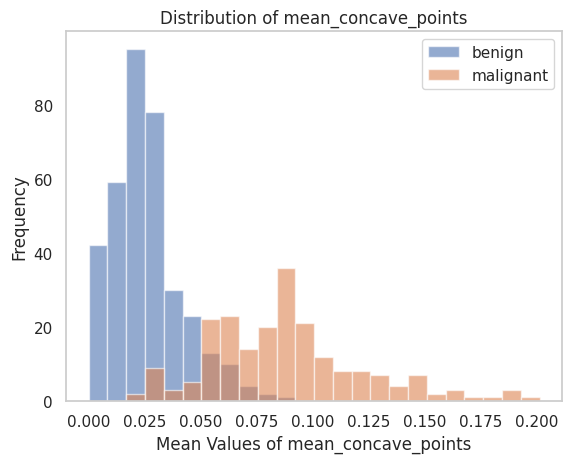

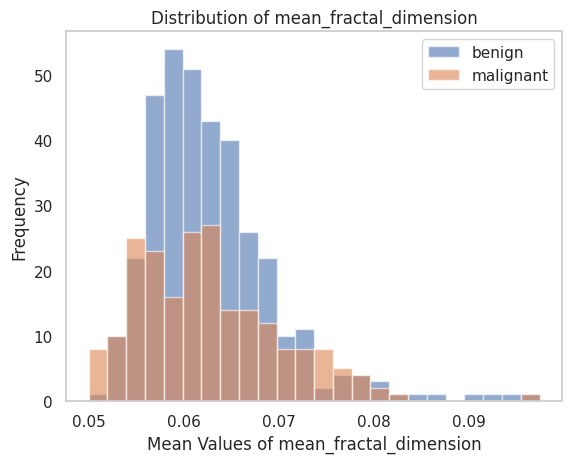

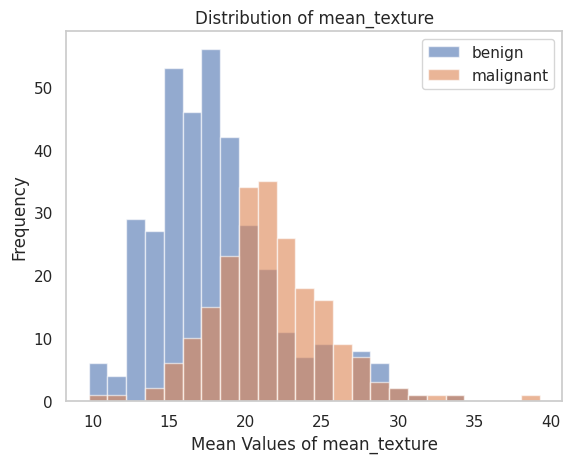

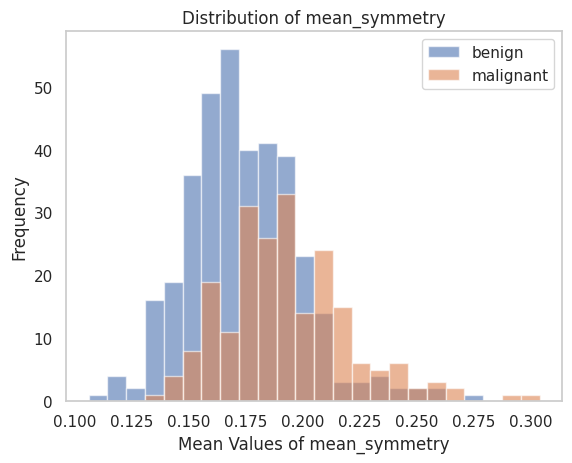

In [ ]:
newData = data[topVars + ["benign"]]
np.round(newData.describe(),4)
benign = newData[newData['benign'] == 1].reset_index(drop= True)
malignant = newData[newData['benign'] ==0].reset_index(drop= True)
for i in newData.columns[:4]:
  bins = np.histogram_bin_edges(newData[i], bins=round(np.sqrt(len(newData[i]))))

  plt.hist(benign[i], bins=bins, alpha=0.6, label= "benign")
  plt.hist(malignant[i], bins=bins, alpha=0.6, label= "malignant")

  plt.title(f'Distribution of {i}')
  plt.xlabel(f'Mean Values of {i}')
  plt.ylabel('Frequency')
  plt.legend()
  plt.grid()
  plt.show()


The histograms show differences in the distributions of the four selected variables between benign and malignant tumours. Malignant tumours generally have higher mean concave points, mean texture, and mean symmetry, while mean fractal dimension shows less separation between the two groups. However, the distributions overlap, indicating that no single variable can perfectly distinguish between benign and malignant tumours.

Text(0.5, 1.02, 'Pairwise Scatter Plots of Benign Tumours')

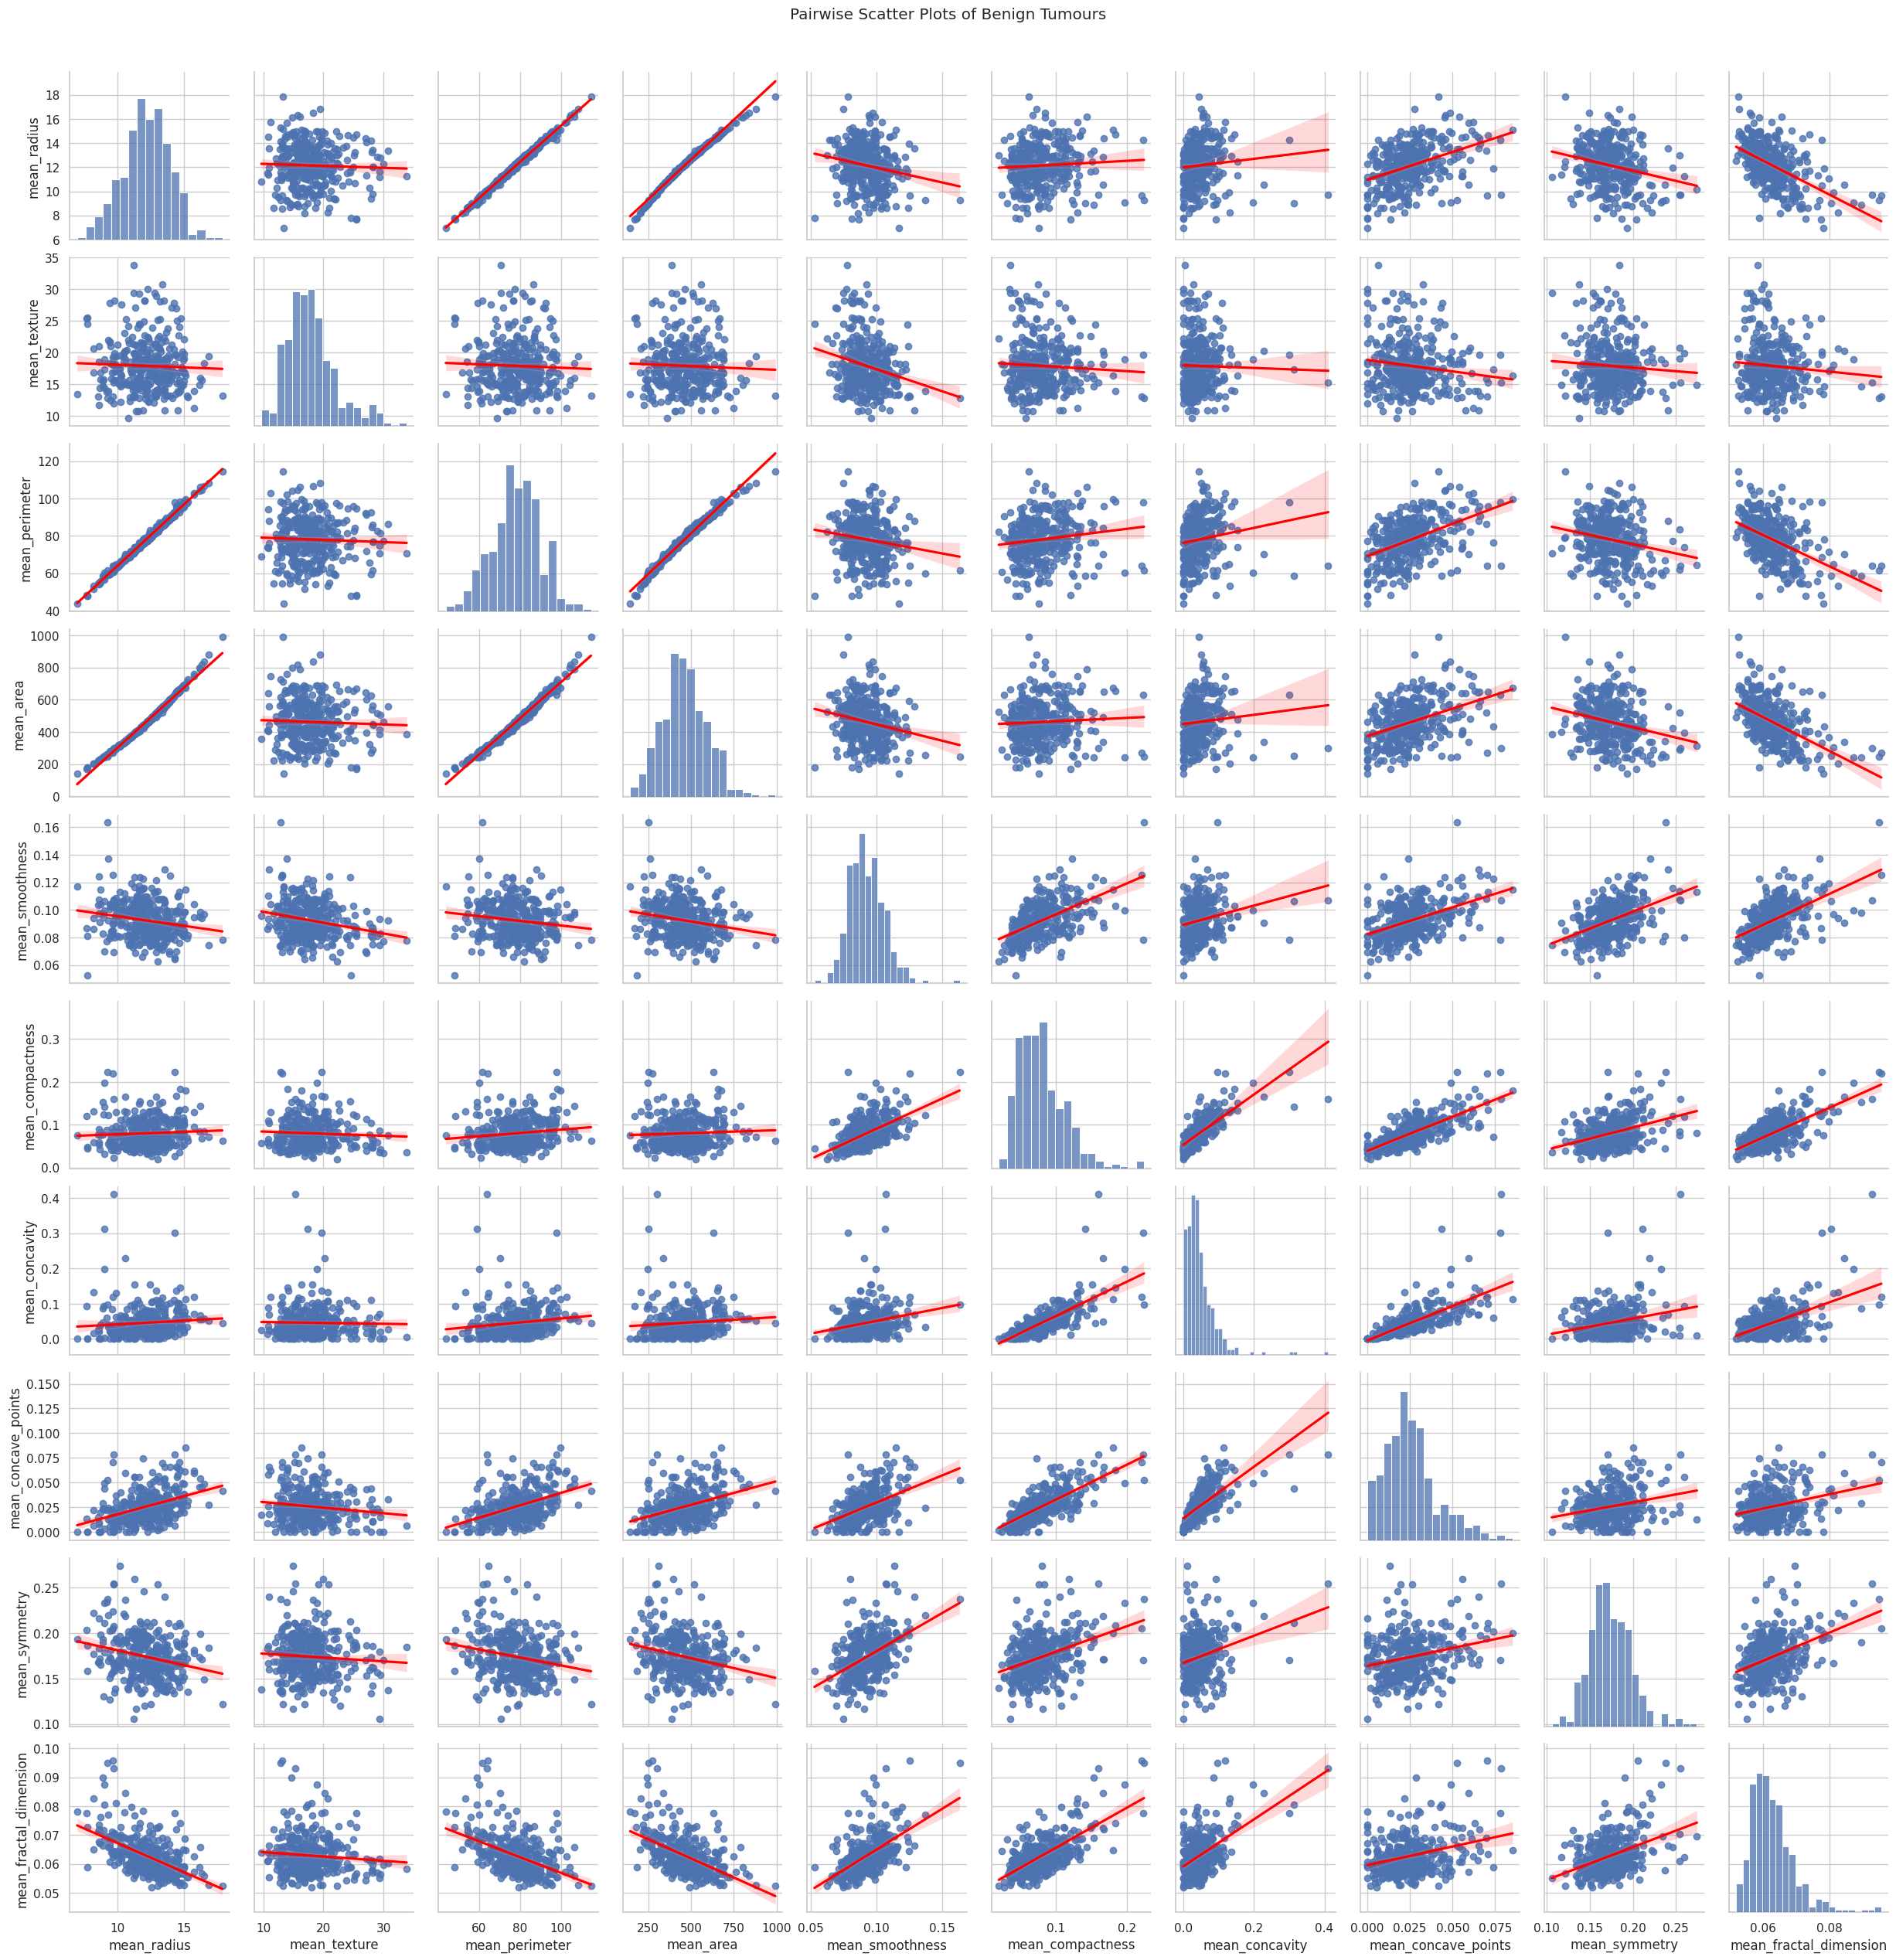

In [ ]:
# Pair Plot of Key Variables for benign Tomur
# keyCol = topVars
# g = sns.pairplot(benign[keyCol], kind="reg", plot_kws={"line_kws": {"color": "red"}})
# g.figure.suptitle("Pairwise Scatter Plots of Benign Tumours", y=1.02)
keyVar = data.columns[:10]


benign = data[data['benign'] == 1][keyVar].reset_index(drop= True)


keyCol = topVars
g = sns.pairplot(benign, kind="reg", plot_kws={"line_kws": {"color": "red"}})
g.figure.suptitle("Pairwise Scatter Plots of Benign Tumours", y=1.02)

Text(0.5, 1.02, 'Pairwise Scatter Plots of Malignant Tumours')

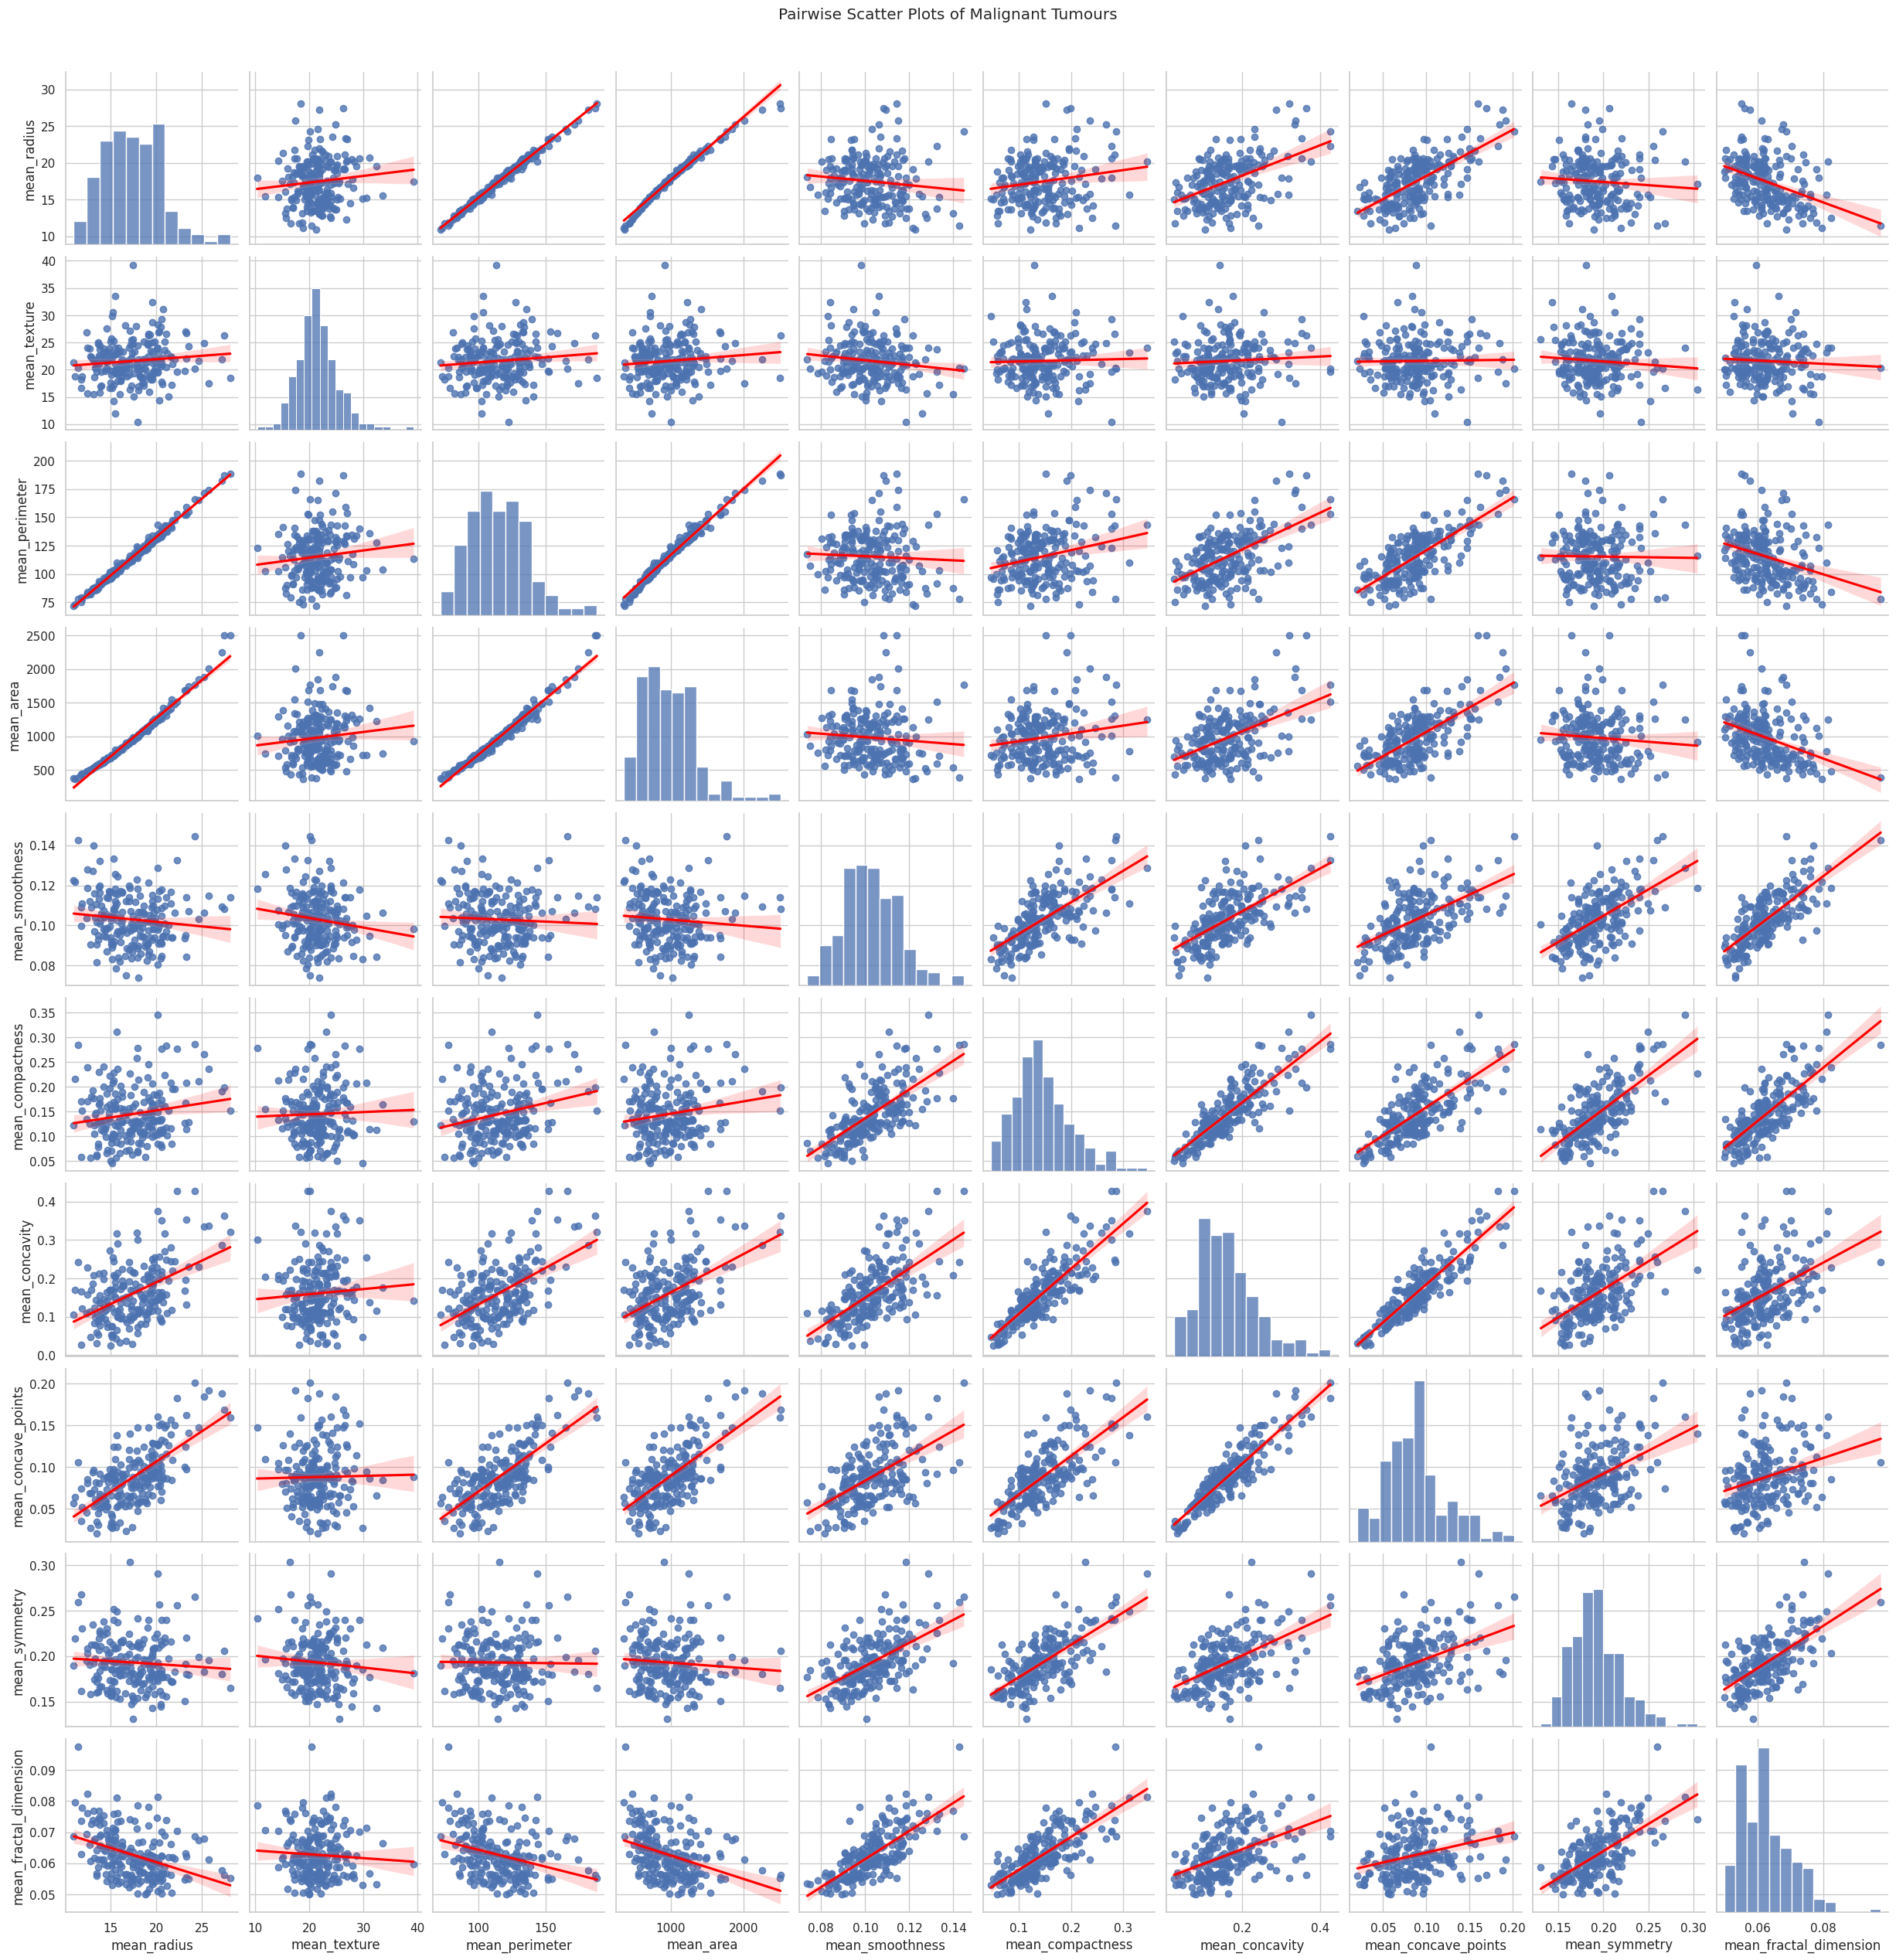

In [ ]:
# Pair Plot of Key Variables for Malignant Tumour
# keyCol = topVars
# g = sns.pairplot(malignant[keyCol], kind="reg", plot_kws={"line_kws": {"color": "red"}})
# g.figure.suptitle("Pairwise Scatter Plots of Malignant Tumours", y=1.02)

malignant = data[data['benign'] ==0][keyVar].reset_index(drop= True)
g = sns.pairplot(malignant, kind="reg", plot_kws={"line_kws": {"color": "red"}})
g.figure.suptitle("Pairwise Scatter Plots of Malignant Tumours", y=1.02)


## Explanation
There exist several significant relationships among the variables representing tumour properties in both malignant and benign groups. For both malignant and benign, the mean radius, mean perimeter, and mean area are nearly perfectly positively correlated. This result indicates that these variables describes similar information about tumour size. Now looking at variables describing the shape irregularity of tumour such as mean compactness, mean concavity, and mean concave points also display significant positive correlations. These relationships become much stronger in the case of malignant tumours.

Now, looking at the larger malignant tumours have higher levels of irregularity of tumour boundaries, this is indicated by the significant positive relationships between the size of tumours and tumour concavity. On the other hand, mean texture usually displays weak relationships with other tumour features, whereas mean fractal dimension correlates negatively with the sizes of tumours. Thus, the interrelationships between the variables are more pronouns in the case of malignant tumours, and tumour size and shape irregularity seem to be important characteristics.

                        mean_radius  mean_texture  mean_perimeter  mean_area  \
mean_radius                   1.000         0.324           0.998      0.987   
mean_texture                  0.324         1.000           0.330      0.321   
mean_perimeter                0.998         0.330           1.000      0.987   
mean_area                     0.987         0.321           0.987      1.000   
mean_smoothness               0.171        -0.023           0.207      0.177   
mean_compactness              0.506         0.237           0.557      0.499   
mean_concavity                0.677         0.302           0.716      0.686   
mean_concave_points           0.823         0.293           0.851      0.823   
mean_symmetry                 0.148         0.071           0.183      0.151   
mean_fractal_dimension       -0.312        -0.076          -0.261     -0.283   

                        mean_smoothness  mean_compactness  mean_concavity  \
mean_radius                       0.171   

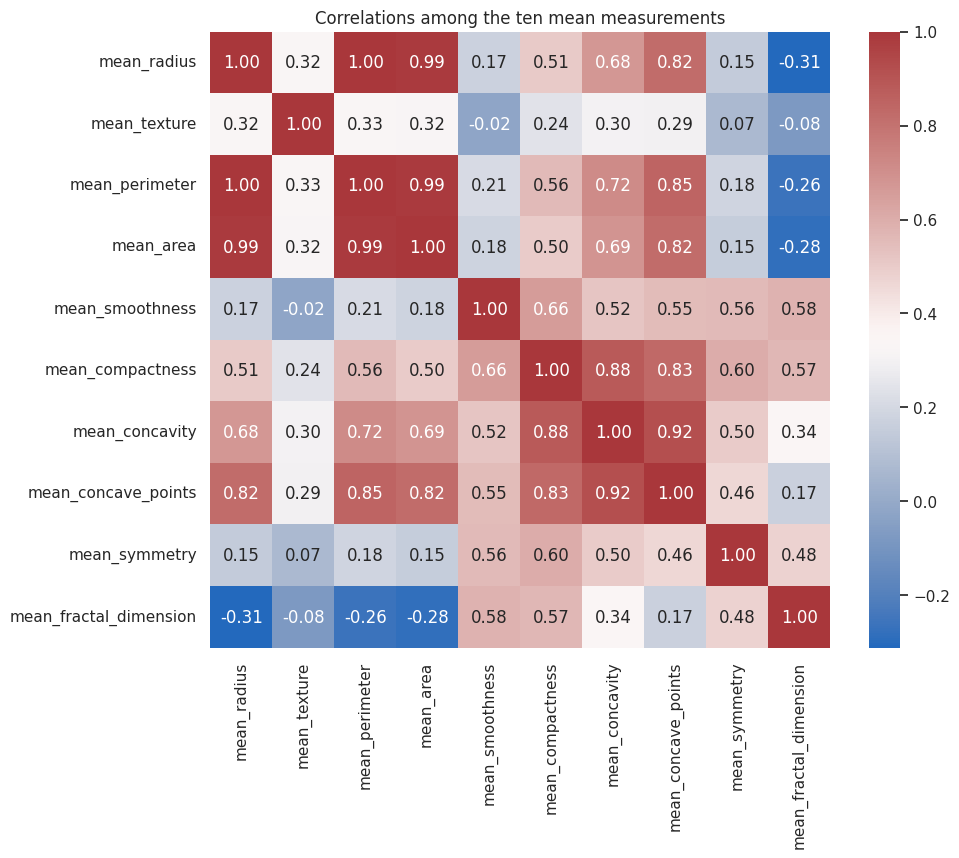

In [ ]:
correl = data[keyVar].corr()
print(correl.round(3))

plt.figure(figsize=(10, 8))
sns.heatmap(correl, annot=True, fmt='.2f', cmap='vlag')
plt.title('Correlations among the ten mean measurements')
plt.show()

The strong correlations between concavity and concave points (r = 0.92), and between compactness and
concavity (r = 0.88), reproduce Project 1's evidence of overlapping information. Within the four
exploratory measurements, symmetry correlates moderately with fractal dimension (r = 0.48) and concave
points (r = 0.46). Texture has weaker correlations with the other three measurements. These are
predictor-to-predictor associations, not causal effects or model coefficients.

## <font color='lightblue'>3. Data wrangling and preprocessing </font>

**Action**: Layout all your data wrangling and preprocessing steps so that a reader will understand why you took each step, and would be able to reproduce your steps. (Marks: 3)

We retain the ten mean measurements as candidate predictors, following Project 1. Error and worst-value
measurements are outside this compact model's scope. technician is excluded because it is a teaching
variable, and benign is used only as the target. The target is already binary, so no further encoding is needed.

We reuse Project 2's stratified random 80/20 split with random_state=2026. Stratification preserves
approximately the original diagnosis proportions. StandardScaler learns means and standard deviations
from the training data only, and those same values are used to transform the test data. Scaling is used for K-means and Logistic Regression; Random Forest uses the same standardized predictors for a consistent comparison.

In [ ]:
from sklearn.model_selection import train_test_split

trainData, testData = train_test_split(
    data, test_size=0.2, stratify=data['benign'], random_state=2026
)

keyVar = data.columns[:10]
scaler = StandardScaler()
XTrain = pd.DataFrame(scaler.fit_transform(trainData[keyVar]), columns=keyVar)
XTest = pd.DataFrame(scaler.transform(testData[keyVar]), columns=keyVar)
yTrain = trainData['benign'].to_numpy()
yTest = testData['benign'].to_numpy()

print('Training observations:', len(yTrain))
print('Test observations:', len(yTest))
print('Training class counts:', trainData['benign'].value_counts().to_dict())
print('Test class counts:', testData['benign'].value_counts().to_dict())

Training observations: 455
Test observations: 114
Training class counts: {1: 285, 0: 170}
Test class counts: {1: 72, 0: 42}


Following the feedback from Project 2, we retain all ten mean features instead of selecting four variables using PCA. Since PCA does not consider the target variable, keeping all ten features may preserve useful information for predicting diagnosis.

## <font color='lightblue'>4. Build and test a model</font>



**Action:** Use your training dataset to build a model with the goal addressing your question of interest. (Marks: 2)

**Logistic regression**

We fit a binary logistic model and inspect its summary.
benign=1, so the estimated probability concerns benign diagnosis. Predictors are all ten standardized mean measurements. We use an intercept and ten additive terms, with no interactions or penalty.
disp=False only suppresses iteration messages.

In [ ]:
df_train = XTrain.copy()
df_train['benign'] = yTrain
df_test = XTest.copy()

# 1. Build the model
formula = 'benign ~ ' + ' + '.join(keyVar)

log_reg = smf.logit(formula, data=df_train)
results = log_reg.fit(disp=False)

print(results.summary())


                           Logit Regression Results                           
Dep. Variable:                 benign   No. Observations:                  455
Model:                          Logit   Df Residuals:                      444
Method:                           MLE   Df Model:                           10
Date:                Fri, 09 Oct 2026   Pseudo R-squ.:                  0.8204
Time:                        18:39:48   Log-Likelihood:                -54.015
converged:                       True   LL-Null:                       -300.69
Covariance Type:            nonrobust   LLR p-value:                 1.163e-99
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept                 -0.9488      0.818     -1.160      0.246      -2.551       0.654
mean_radius               -4.2031     16.955     -0.248      0.804     -37.433      29.027
mean

In [ ]:
vif = pd.DataFrame()
vif['Variable'] = XTrain.columns
vif['VIF'] = [variance_inflation_factor(XTrain.values, i)
    for i in range(XTrain.shape[1])]
print(vif)

                 Variable          VIF
0             mean_radius  1892.817303
1            mean_texture     1.158704
2          mean_perimeter  2284.069488
3               mean_area    54.754309
4         mean_smoothness     2.747858
5        mean_compactness    24.362817
6          mean_concavity    13.565870
7     mean_concave_points    22.577895
8           mean_symmetry     1.751252
9  mean_fractal_dimension     5.821757


- **Outcome and observations:** The outcome variable, `benign`, is binary. Each row represents one observation. Independence is assumed based on the study design.

- **Multicollinearity:** VIF is used to check whether the predictors are highly correlated. VIF values close to 1 indicate little multicollinearity, while values above 5 may indicate a problem.


Note, logistic regression does not require the predictors or residuals to be normally distributed.

**K means**

Selected k: 2


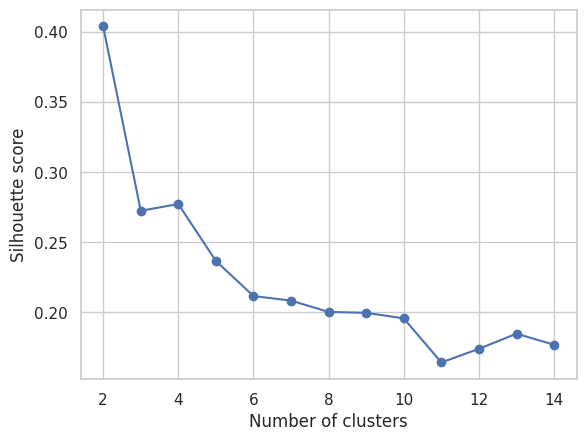

In [ ]:
# K means
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kRange = range(2, 15)
silScores = []
for k in kRange:
    model = KMeans(n_clusters=k, n_init=10, random_state=2026)
    model.fit(XTrain)
    silScores.append(silhouette_score(XTrain, model.labels_))

bestK = list(kRange)[np.argmax(silScores)]
print('Selected k:', bestK)
plt.plot(list(kRange), silScores, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette score')
plt.show()

In [ ]:
# 1. Build the model
kmeans = KMeans(n_clusters=bestK, n_init=10, random_state=2026)

# 2. Fit the model
kmeans.fit(XTrain)

# Match clusters to diagnoses using training labels
clusterTable = pd.crosstab(kmeans.labels_, yTrain)
clusterLabels = clusterTable.idxmax(axis=1)
print(clusterTable)


col_0    0    1
row_0          
0      127    3
1       43  282


**Random Forest**

Our target is benign (1 = benign; 0 = malignant). Random Forest is appropriate for this supervised classification task because it learns from diagnosis labels and can capture nonlinear relationships and interactions. We retain 200 trees and the fixed random seed; the test set is not used to tune the model.


In [ ]:
from sklearn.ensemble import RandomForestClassifier

# 1. Build the model
modelRandomForest = RandomForestClassifier(
    n_estimators=200, oob_score=True, random_state=2026
)

# 2. Fit the model
modelRandomForest.fit(XTrain, yTrain)

RandomForestClassifier(n_estimators=200, oob_score=True, random_state=2026)

In [ ]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance
perm_result = permutation_importance(
    modelRandomForest,
    XTest,
    yTest,
    scoring='accuracy',
    n_repeats=30,
    random_state=2026
)

# Display the results
forest_importances = pd.DataFrame({
    'variable': XTest.columns,
    'impo': perm_result.importances_mean,
    'sd': perm_result.importances_std
}).sort_values('impo', ascending=False)

forest_importances.round(4)

,variable,impo,sd
7,mean_concave_points,0.0538,0.0226
1,mean_texture,0.0243,0.0144
3,mean_area,0.0193,0.0144
6,mean_concavity,0.0129,0.0190
0,mean_radius,0.0096,0.0118
2,mean_perimeter,0.0047,0.0135
8,mean_symmetry,0.0035,0.0054
5,mean_compactness,0.0026,0.0046
9,mean_fractal_dimension,-0.0047,0.0049
4,mean_smoothness,-0.0070,0.0062


**Q4**: Measure the performance of your model, and describe how well your model generalizes to new data (Marks: 2)

All methods are evaluated on the same 114 cases. Accuracy is the overall fraction correct. Benign
precision is the fraction of predicted benign cases that are actually benign; malignant recall is the
fraction of actual malignant cases detected (pos_label=0).

**Logistic model**

In [ ]:
# Predict the probability of a benign diagnosis
df_test['benign_prob'] = results.predict(df_test)

# Convert probabilities into predicted diagnoses
df_test['benign_pred'] = (df_test['benign_prob'] > 0.5).astype(int)

# Calculate test accuracy
print('Logistic accuracy:', accuracy_score(yTest, df_test['benign_pred']))

logPred = df_test['benign_pred']
print('Logistic regression confusion matrix:')
print(confusion_matrix(yTest, logPred, labels=[1, 0]))
print('Precision (benign):', precision_score(yTest, logPred))
print('Recall (malignant):', recall_score(yTest, logPred, pos_label=0))
logTrainPred = (results.predict(df_train) > 0.5).astype(int)
print('Training accuracy:', accuracy_score(yTrain, logTrainPred))

Logistic accuracy: 0.9122807017543859
Logistic regression confusion matrix:
[[66  6]
 [ 4 38]]
Precision (benign): 0.9428571428571428
Recall (malignant): 0.9047619047619048
Training accuracy: 0.9472527472527472


**K Mean Performance**

In [ ]:
# Predict using K-means and the training-derived cluster labels
testClusters = kmeans.predict(XTest)
kPred = pd.Series(testClusters).map(clusterLabels)

print('K-means confusion matrix:')
print(confusion_matrix(yTest, kPred, labels=[1, 0]))
print('Accuracy:', accuracy_score(yTest, kPred))
print('Precision (benign):', precision_score(yTest, kPred))
print('Recall (malignant):', recall_score(yTest, kPred, pos_label=0))

K-means confusion matrix:
[[69  3]
 [ 9 33]]
Accuracy: 0.8947368421052632
Precision (benign): 0.8846153846153846
Recall (malignant): 0.7857142857142857


**Random Forest Performance**

In [ ]:
# Predict using Random Forest
rfPred = modelRandomForest.predict(XTest)

print('Random Forest confusion matrix:')
print(confusion_matrix(yTest, rfPred, labels=[1, 0]))
print('Accuracy:', accuracy_score(yTest, rfPred))
print('Precision (benign):', precision_score(yTest, rfPred))
print('Recall (malignant):', recall_score(yTest, rfPred, pos_label=0))
print('Training accuracy:', modelRandomForest.score(XTrain, yTrain))

# Compare with always predicting the most common training diagnosis
majorityClass = pd.Series(yTrain).mode()[0]
print('Baseline test accuracy:', (yTest == majorityClass).mean())

Random Forest confusion matrix:
[[68  4]
 [ 3 39]]
Accuracy: 0.9385964912280702
Precision (benign): 0.9577464788732394
Recall (malignant): 0.9285714285714286
Training accuracy: 1.0
Baseline test accuracy: 0.631578947368421


In [ ]:
# Create model comparison table
comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest',
        'K-means'
    ],

    'Accuracy (%)': [
        accuracy_score(yTest, logPred) * 100,
        accuracy_score(yTest, rfPred) * 100,
        accuracy_score(yTest, kPred) * 100
    ],

    'Benign Precision (%)': [
        precision_score(yTest, logPred) * 100,
        precision_score(yTest, rfPred) * 100,
        precision_score(yTest, kPred) * 100
    ],

    'Malignant Recall (%)': [
        recall_score(yTest, logPred, pos_label=0) * 100,
        recall_score(yTest, rfPred, pos_label=0) * 100,
        recall_score(yTest, kPred, pos_label=0) * 100
    ]
})

comparison = comparison.round(2)

comparison

,Model,Accuracy (%),Benign Precision (%),Malignant Recall (%)
0,Logistic Regression,91.23,94.29,90.48
1,Random Forest,93.86,95.77,92.86
2,K-means,89.47,88.46,78.57


Random Forest correctly classified 107/114 cases (93.86%), logistic regression 104/114 (91.23%), K-means 102/114 (89.47%), and the baseline 72/114 (63.16%).

Logistic regression detected 38/42 malignant cases (90.48% recall), while Random Forest detected 39/42 (92.86%). Random Forest achieved the highest benign precision (95.77%) and malignant recall (92.86%) among the three models.

K-means detected 33/42 malignant cases (78.57% recall). However, its overall accuracy (89.47%) remained lower than that of the supervised models.

Logistic regression achieved 94.73% training accuracy and 91.23% test accuracy. Random Forest achieved 100% training accuracy and 93.86% test accuracy. The differences suggest some degree of overfitting, particularly for Random Forest, although its test performance remained strong.

## <font color='lightblue'>5. Interpret your model</font>

**Q5**: Interpret your model results. E.g., what features contributed to your predictions, if possible, can you determine the sign and magnitude of the effect (Marks: 2).

## Model Interpretation and Comparison

### Logistic Regression

The logistic regression model describes how each predictor is associated with the estimated log-odds of a benign diagnosis, holding the other predictors constant. Since the predictors were standardized using the training data, each coefficient represents a **one-standard-deviation increase** in the corresponding measurement.

- **Mean concave points** had a negative coefficient (**−3.332**), indicating that higher values were associated with lower estimated odds of a benign diagnosis.
- **Mean texture** also had a negative coefficient (**−1.641**). A one-standard-deviation increase in texture multiplies the estimated benign odds by approximately **0.194**.
- **Mean fractal dimension** had a positive coefficient (**0.324**), indicating higher estimated benign odds after adjusting for the other predictors.
- **Mean symmetry** had a small coefficient (**−0.230**) and a p-value of **0.527**, providing little evidence of an independent association.

The VIF values ranged from **1.159 to 2284.069**, indicating substantial multicollinearity among some predictors. The model also reported possible **quasi-separation**, so individual coefficients should be interpreted cautiously.

---

### Random Forest

Permutation importance was used to measure how much the model's predictive accuracy depended on each predictor.

- **Mean concave points** had the highest permutation importance in this model. Shuffling it reduced test accuracy by an average of **5.38 percentage points**.
- **Mean texture** ranked second, reducing accuracy by **2.43 percentage points**.
- **Mean fractal dimension** had a negative permutation importance (**−0.47 percentage points**).
- **Mean symmetry** had near-zero importance (**0.35 percentage points**).

A negative permutation importance does **not** mean that the predictor has a negative relationship with diagnosis. It only means that shuffling the variable did not reduce predictive performance.

Overall, both logistic regression and Random Forest suggest that **mean concave points** and **mean texture** are particularly informative predictors, although logistic regression coefficient estimates should be interpreted cautiously.

---

### K-means

K-means grouped observations based on similarities in the ten standardized measurements without using diagnosis labels during model fitting.

Two clusters were selected based on the **silhouette score**. The majority diagnosis within each training cluster was then used to assign a predicted class.

The model achieved:

- **Test accuracy:** 89.47%
- **Malignant recall:** 78.57%

These results suggest that the measurements contain some natural grouping related to diagnosis, although the clusters did not fully separate benign and malignant cases.

Unlike logistic regression, K-means does not provide signed coefficients. Individual variable contributions to clustering were also not quantified in this analysis.

---

### Model Comparison

Random Forest achieved the best test performance, with an accuracy of **93.86%** and a malignant recall of **92.86%**.

It correctly classified **107 of 114** test observations and identified **39 of 42** malignant cases. Logistic regression correctly classified **104 of 114** observations and identified **38 of 42** malignant cases.

Based on its higher test accuracy and malignant recall, **Random Forest was selected as the preferred predictive model**. Logistic regression remained useful for interpreting predictor relationships, while K-means provided insight into the natural grouping of the observations.

## <font color='lightblue'>6. Answer your question</font>

**Q6:** Use your analysis above to answer your question of interest. Did you achieve your desired outcome, and what might the next steps be? Remember to write as though you are writing to team mates working on the same/similar problem. (Marks: 3)


Note: It is ok if your analysis doesn't provide a strong answer, you can point out where it failed. If anything you can cross the approach you took off the list of possible ways to tackle your question. I.e., you still made progress!

Our analysis suggests that the ten mean features can be used to distinguish between benign and malignant tumours. Both logistic regression and Random Forest identified **mean concave points** and **mean texture** as informative predictors, while mean symmetry contributed relatively little. However, the logistic regression coefficients should be interpreted cautiously due to multicollinearity and possible quasi-separation.

Overall, we achieved our desired outcome. **Random Forest was selected as the preferred predictive model**, with a test accuracy of **93.86%** and a malignant recall of **92.86%**. It correctly classified **107 of 114** test observations and identified **39 of 42** malignant cases. Logistic regression also performed well, with an accuracy of **91.23%**, while K-means had a lower accuracy of **89.47%**. This suggests that the supervised models were more effective than K-means for predicting diagnosis using the ten mean features.

For future work, we could explore whether other variables in the dataset provide additional useful information for distinguishing benign and malignant tumours. We could also apply the models to new data to see whether the patterns found in this analysis remain consistent.